# 4.33 Transmon Analytics

This demo notebook demonstrates how to use the transmon_analytics.py file to create plots of the transmon qubit Cooper pair box eigenvalues as a function of offset charge (ng). These plots can be found the original transmon qubit paper (J. Kock et al., Phys. Rev. A 76, 042319 (2007).) Here we consider the first four energy levels (m=0 through m=3) as a function of offset charge for the case where the ratio of Josephson to charing energy is equal to one ($E_{J} / E_{C} = 1.0$.)   

In [1]:
import qiskit_metal as metal
from qiskit_metal.analyses.hamiltonian.transmon_analytics import *

The function which actually creates the plots is called "plot_eigenvalues" and it does not take any arguments. So, we can create the plot(s) simply by executing the following command:

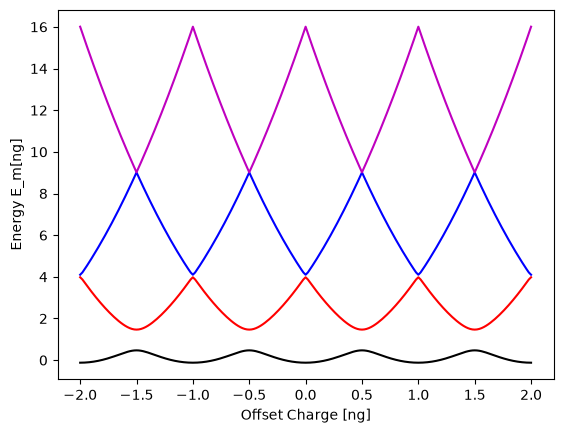

In [2]:
plot_eigenvalues()

The module-level plot uses $E_J/E_C = 1$. For other ratios or higher levels, call `transmon_eigenvalue(m, ng, Ej_over_Ec, Ec)` directly. It evaluates Koch et al., Eq. (2.11): the even Mathieu characteristic value $a$ for the even levels and the odd one, $b$, for the odd levels at $n_g = 0$ and $1/2$, and the Hill matrix of the Mathieu equation for any other $n_g$. Here are the first four levels of a transmon with $E_J/E_C = 5$, where the charge dispersion is still visible (compare Koch et al., Fig. 2), relative to the ground state at $n_g = 1/2$ and in units of the transition energy $E_{01}$ there:

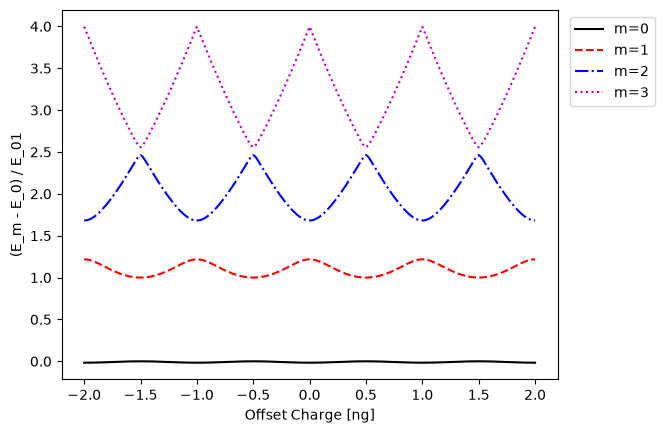

In [3]:
import numpy as np
import matplotlib.pyplot as plt

ngs = np.linspace(-2.0, 2.0, 201)
ratio = 5.0
E = np.array([[transmon_eigenvalue(m, x, ratio, 1.0) for x in ngs] for m in range(4)])
E00 = transmon_eigenvalue(0, 0.5, ratio, 1.0)
E01 = transmon_eigenvalue(1, 0.5, ratio, 1.0) - E00
for m, style in zip(range(4), ["k-", "r--", "b-.", "m:"]):
    plt.plot(ngs, (E[m] - E00) / E01, style, label=f"m={m}")
plt.xlabel("Offset Charge [ng]")
plt.ylabel("(E_m - E_0) / E_01")
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.show()